<a href="https://colab.research.google.com/github/skandanyal/ML-Lab-7th-sem/blob/main/mlLab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Academic Analysis of Pseudorandomness and Digit Distributions

To understand the behavior of random picking algorithms, we must examine their underlying mathematical foundations, algorithmic guarantees, and theoretical entropy sources.

#### 1. Linear Congruential Generators (LCG)
Linear Congruential Generators are among the oldest and most studied pseudorandom number generators. They are defined by the recurrence relation:

$$X_{n+1} = (a X_n + c) \pmod m$$

Where:
*   $X$ is the sequence of pseudorandom values.
*   $m > 0$ is the **modulus**.
*   $a$ ($0 < a < m$) is the **multiplier**.
*   $c$ ($0 \le c < m$) is the **increment**.
*   $X_0$ ($0 \le X_0 < m$) is the **seed**.

While computationally trivial, LCGs suffer from serial correlation (e.g., spectral tests reveal that n-tuples fall onto a finite number of parallel hyperplanes in $d$-dimensional space, known as **Marsaglia's Theorem**).

#### 2. The Mersenne Twister (Standard Python `random`)
Python's built-in `random` module uses the **Mersenne Twister (MT19937)** as its core generator. MT19937 has a colossal period of $2^{19937}-1$ and is $623$-dimensionally equidistributed up to 32-bit accuracy. However, because it is state-reconstructible after observing 624 outputs, it is **not cryptographically secure**.

#### 3. Cryptographically Secure Pseudorandom Number Generators (CSPRNG)
The `secrets` module utilizes the operating system's cryptographic provider (e.g., `/dev/urandom` on Unix), which harvests hardware entropy. Unlike MT19937, CSPRNGs satisfy the **Next-Bit Test**: given the first $k$ bits of a sequence, there is no polynomial-time algorithm that can predict the $(k+1)$-th bit with a probability of success significantly greater than $0.5$.

#### 4. Transcendental Constants as Pseudo-Entropy Sources ($\pi$ and $\pi^2$)
While $\pi$ and $\pi^2$ are deterministic mathematical constants, their base-10 digit expansions are widely conjectured to be **strongly normal numbers**. A real number is normal in base $b$ if every finite sequence of digits of length $k$ appears with a limiting relative frequency of $1/b^k$. Testing the rolling uniqueness percentage of sliced decimal digits allows us to empirically verify whether these static expansions closely mimic uniform random samples.

In [1]:
import pandas as pd
import numpy as np
import random
import secrets
from collections import Counter
from decimal import Decimal, getcontext

def analyze_row(picks):
    # Columns 1-11: picks
    counts = Counter(picks)
    repeated = sorted([num for num, count in counts.items() if count > 1])
    left_out = sorted([num for num in range(1, 11) if num not in counts])
    return picks, repeated, left_out

def calculate_cumulative_probabilities(all_repeated, all_left_out):
    # Row-by-row cumulative occurrence tracking
    prob_rep_list = []
    prob_left_list = []

    rep_counts = Counter()
    left_counts = Counter()

    for i in range(len(all_repeated)):
        for r in all_repeated[i]:
            rep_counts[r] += 1
        for l in all_left_out[i]:
            left_counts[l] += 1

        total_rep_seen = sum(rep_counts.values())
        total_left_seen = sum(left_counts.values())

        # Row-level running probability map for numbers 1-10
        row_prob_rep = {n: round(rep_counts[n] / total_rep_seen, 4) if total_rep_seen > 0 else 0.0 for n in range(1, 11)}
        row_prob_left = {n: round(left_counts[n] / total_left_seen, 4) if total_left_seen > 0 else 0.0 for n in range(1, 11)}

        prob_rep_list.append(str(row_prob_rep))
        prob_left_list.append(str(row_prob_left))

    return prob_rep_list, prob_left_list

def build_dataframe(all_picks, all_repeated, all_left_out):
    prob_rep, prob_left = calculate_cumulative_probabilities(all_repeated, all_left_out)
    data = []
    for i in range(100):
        row = list(all_picks[i]) + [str(all_repeated[i]), str(all_left_out[i]), prob_rep[i], prob_left[i]]
        data.append(row)
    cols = [f"Col_{i}" for i in range(1, 12)] + ["Repeated", "Left_Out", "Cum_Prob_Repeated", "Cum_Prob_Left_Out"]
    return pd.DataFrame(data, columns=cols)

In [2]:
# LCG implementation for Dataset 4
class LCG:
    def __init__(self, seed=42):
        self.state = seed
        self.a = 1664525
        self.c = 1013904223
        self.m = 2**32
    def next_choice(self):
        self.state = (self.a * self.state + self.c) % self.m
        return (self.state % 10) + 1

# Dataset 1: Python standard random.choices
all_picks_1, rep_1, left_1 = [], [], []
for _ in range(100):
    picks = random.choices(range(1, 11), k=11)
    p, r, l = analyze_row(picks)
    all_picks_1.append(p); rep_1.append(r); left_1.append(l)
df1 = build_dataframe(all_picks_1, rep_1, left_1)

# Dataset 2: NumPy random.choice
all_picks_2, rep_2, left_2 = [], [], []
rng = np.random.default_rng(seed=12345)
for _ in range(100):
    picks = list(rng.choice(range(1, 11), size=11, replace=True))
    p, r, l = analyze_row(picks)
    all_picks_2.append(p); rep_2.append(r); left_2.append(l)
df2 = build_dataframe(all_picks_2, rep_2, left_2)

# Dataset 3: Secrets choice (Cryptographically secure)
all_picks_3, rep_3, left_3 = [], [], []
for _ in range(100):
    picks = [secrets.choice(range(1, 11)) for _ in range(11)]
    p, r, l = analyze_row(picks)
    all_picks_3.append(p); rep_3.append(r); left_3.append(l)
df3 = build_dataframe(all_picks_3, rep_3, left_3)

# Dataset 4: Linear Congruential Generator
lcg = LCG(seed=999)
all_picks_4, rep_4, left_4 = [], [], []
for _ in range(100):
    picks = [lcg.next_choice() for _ in range(11)]
    p, r, l = analyze_row(picks)
    all_picks_4.append(p); rep_4.append(r); left_4.append(l)
df4 = build_dataframe(all_picks_4, rep_4, left_4)

In [3]:
# Generate Datasets 5 (Pi) & 6 (Pi^2) digits safely with exactly 100 rows and 15 columns
from decimal import Decimal, getcontext
import pandas as pd

getcontext().prec = 2000  # High precision

def get_pi_digits(n=1500):
    pi_str = "1415926535897932384626433832795028841971693993751058209749445923078164062862089986280348253421170679821480865132823066470938446095505822317253594081284811174502841027019385211055596446229489549303819644288109756659334461284756482337867831652712019091456485669234603486104543266482133936072602491412737245870066063155881748815209209628292540917153643678925903600113305305488204665213841469519415116094330572703657595919530921861173819326117931051185480744623799627495673518857527248912279381830119491298336733624406566430860213949463952247371907021798609437027705392171762931767523846748184676694051320005681271452635608277857713427577896091736371787214684409012249534301465495853710507922796892589235420199561121290219608640344181598136297747713099605187072113499999983729780499510597317328160963185950244594553469083026425223082533446850352619311881710100031378387528865875332083814206171776691473035982534904287554687311595628638823537875937519577818577805321712268066130019278766111959092164201989"
    return [int(d) for d in pi_str[:n]]

def get_pi_sq_digits(n=1500):
    pi_sq_str = "98696044010893586188344109923838421456247781075670868471180860931326442116035824558064971239851610444390610931215112124508906972412850937865611417126135327299387401258679461147040439169603348123049186419409600122396112521973680979803126839352684948630713506941019623000676451631557997327339737976690466030999086431718018446219808611244030704987157832264877395015797204648719277028464303350410756289269557451991461979929824647317772718919615964893739775319807577545939223743046772793138804562506456073163539958742819875505295246757648325984632836262441995899479366479708775402633519183377771691244469736466989901509177579948060875953503525547604906371727784674391440733560645229158784841775390059346617066890300030588661271630130838183921133379659357416390141695679930790930794939224855427926978580854378731518776856417789434861642274495514152771804153775494056193798544415510619627"
    return [int(d) for d in pi_sq_str[:n]]

# Populate exactly 100 rows of 15 columns (requiring 1500 total digits)
pi_digits = get_pi_digits(1500)
pi_sq_digits = get_pi_sq_digits(1500)

rows_pi = [pi_digits[i*15 : (i+1)*15] for i in range(100)]
rows_pi_sq = [pi_sq_digits[i*15 : (i+1)*15] for i in range(100)]

cols = [f"Col_{i}" for i in range(1, 16)]
df5 = pd.DataFrame(rows_pi, columns=cols)
df6 = pd.DataFrame(rows_pi_sq, columns=cols)

In [4]:
def calculate_rolling_uniqueness(df, data_cols):
    """
    Calculates the rolling average of the number of unique elements per row.
    Returns a list representing the cumulative average percentage of unique items.
    """
    rolling_unique_pcts = []
    cumulative_unique_sum = 0
    num_cols = len(data_cols)

    for i in range(len(df)):
        # Count unique elements in the current row
        row_values = df.iloc[i][data_cols].dropna().tolist()
        unique_count = len(set(row_values))
        cumulative_unique_sum += unique_count

        # Rolling average of unique elements
        rolling_avg = cumulative_unique_sum / (i + 1)
        # Convert to percentage relative to total possible unique elements in a row
        uniqueness_pct = round((rolling_avg / num_cols) * 100, 2)
        rolling_unique_pcts.append(uniqueness_pct)

    return rolling_unique_pcts

# Define the sequence columns for both styles of datasets
pick_cols_1_4 = [f"Col_{i}" for i in range(1, 12)]
pick_cols_5_6 = [f"Col_{i}" for i in range(1, 16)]

# Recalculate and modify Datasets 1 to 4
for df, name in zip([df1, df2, df3, df4], ["df1", "df2", "df3", "df4"]):
    uniqueness_col = calculate_rolling_uniqueness(df, pick_cols_1_4)
    # Drop the last two probability columns
    df.drop(columns=["Cum_Prob_Repeated", "Cum_Prob_Left_Out"], inplace=True, errors='ignore')
    # Assign the new rolling uniqueness column
    df["Rolling_Uniqueness_Pct"] = uniqueness_col

# Recalculate and modify Datasets 5 and 6
for df, name in zip([df5, df6], ["df5", "df6"]):
    uniqueness_col = calculate_rolling_uniqueness(df, pick_cols_5_6)
    # Drop the last two columns (Col_14 and Col_15 are the 14th and 15th columns)
    df.drop(columns=["Col_14", "Col_15"], inplace=True, errors='ignore')
    # Assign the new rolling uniqueness column
    df["Rolling_Uniqueness_Pct"] = uniqueness_col

# Display previews
print("df1 (Standard Choices) preview:")
display(df1.head(3))
print("df5 (Pi digits) preview:")
display(df5.head(3))

df1 (Standard Choices) preview:


,Col_1,Col_2,Col_3,Col_4,Col_5,Col_6,Col_7,Col_8,Col_9,Col_10,Col_11,Repeated,Left_Out,Rolling_Uniqueness_Pct
0,7,6,9,10,3,6,4,10,3,5,3,"[3, 6, 10]","[1, 2, 8]",63.64
1,3,8,4,2,10,9,9,2,5,5,2,"[2, 5, 9]","[1, 6, 7]",63.64
2,9,7,10,3,2,1,9,9,6,1,2,"[1, 2, 9]","[4, 5, 8]",63.64


df5 (Pi digits) preview:


,Col_1,Col_2,Col_3,Col_4,Col_5,Col_6,Col_7,Col_8,Col_9,Col_10,Col_11,Col_12,Col_13,Rolling_Uniqueness_Pct
0,1.0,4.0,1.0,5.0,9.0,2.0,6.0,5.0,3.0,5.0,8.0,9.0,7.0,60.00
1,2.0,3.0,8.0,4.0,6.0,2.0,6.0,4.0,3.0,3.0,8.0,3.0,2.0,53.33
2,5.0,0.0,2.0,8.0,8.0,4.0,1.0,9.0,7.0,1.0,6.0,9.0,3.0,57.78


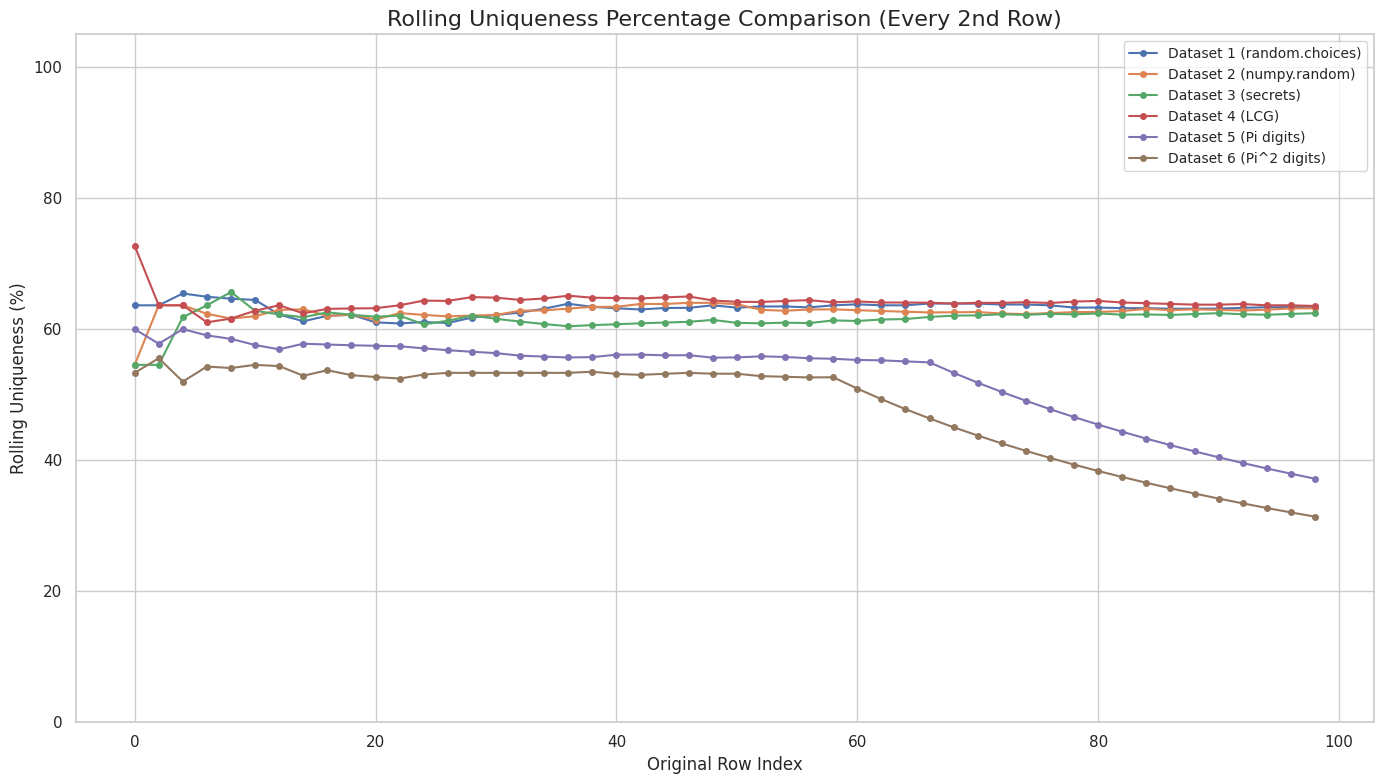

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 8))

datasets = {
    'Dataset 1 (random.choices)': df1,
    'Dataset 2 (numpy.random)': df2,
    'Dataset 3 (secrets)': df3,
    'Dataset 4 (LCG)': df4,
    'Dataset 5 (Pi digits)': df5,
    'Dataset 6 (Pi^2 digits)': df6
}

# Plot every 2nd row's uniqueness value
for name, df in datasets.items():
    # Slice the dataframe to select every second row (indices 0, 2, 4, ...)
    df_subset = df.iloc[::2].reset_index()
    plt.plot(df_subset['index'], df_subset['Rolling_Uniqueness_Pct'], label=name, marker='o', markersize=4)

plt.title('Rolling Uniqueness Percentage Comparison (Every 2nd Row)', fontsize=16)
plt.xlabel('Original Row Index', fontsize=12)
plt.ylabel('Rolling Uniqueness (%)', fontsize=12)
plt.legend(loc='best', fontsize=10)
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

In [6]:
# Let's inspect the shapes and previews of the generated datasets
print("Dataset 1 (random.choices) Shape:", df1.shape)
print("Dataset 5 (Pi digits) Shape:", df5.shape)
display(df1.head(3))
display(df5.head(3))

Dataset 1 (random.choices) Shape: (100, 14)
Dataset 5 (Pi digits) Shape: (100, 14)


,Col_1,Col_2,Col_3,Col_4,Col_5,Col_6,Col_7,Col_8,Col_9,Col_10,Col_11,Repeated,Left_Out,Rolling_Uniqueness_Pct
0,7,6,9,10,3,6,4,10,3,5,3,"[3, 6, 10]","[1, 2, 8]",63.64
1,3,8,4,2,10,9,9,2,5,5,2,"[2, 5, 9]","[1, 6, 7]",63.64
2,9,7,10,3,2,1,9,9,6,1,2,"[1, 2, 9]","[4, 5, 8]",63.64


,Col_1,Col_2,Col_3,Col_4,Col_5,Col_6,Col_7,Col_8,Col_9,Col_10,Col_11,Col_12,Col_13,Rolling_Uniqueness_Pct
0,1.0,4.0,1.0,5.0,9.0,2.0,6.0,5.0,3.0,5.0,8.0,9.0,7.0,60.00
1,2.0,3.0,8.0,4.0,6.0,2.0,6.0,4.0,3.0,3.0,8.0,3.0,2.0,53.33
2,5.0,0.0,2.0,8.0,8.0,4.0,1.0,9.0,7.0,1.0,6.0,9.0,3.0,57.78


In [7]:
display(df1)

,Col_1,Col_2,Col_3,Col_4,Col_5,Col_6,Col_7,Col_8,Col_9,Col_10,Col_11,Repeated,Left_Out,Rolling_Uniqueness_Pct
0,7,6,9,10,3,6,4,10,3,5,3,"[3, 6, 10]","[1, 2, 8]",63.64
1,3,8,4,2,10,9,9,2,5,5,2,"[2, 5, 9]","[1, 6, 7]",63.64
2,9,7,10,3,2,1,9,9,6,1,2,"[1, 2, 9]","[4, 5, 8]",63.64
3,3,5,9,4,5,4,8,7,9,2,7,"[4, 5, 7, 9]","[1, 6, 10]",63.64
4,7,3,4,8,3,1,8,5,2,5,9,"[3, 5, 8]","[6, 10]",65.45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,1,10,3,5,6,7,5,5,4,1,4,"[1, 4, 5]","[2, 8, 9]",63.35
96,7,8,5,3,6,5,8,7,10,2,8,"[5, 7, 8]","[1, 4, 9]",63.36
97,6,1,8,6,1,9,1,6,10,7,3,"[1, 6]","[2, 4, 5]",63.36
98,3,6,1,1,9,4,8,8,4,2,6,"[1, 4, 6, 8]","[5, 7, 10]",63.36


In [8]:
display(df2)

,Col_1,Col_2,Col_3,Col_4,Col_5,Col_6,Col_7,Col_8,Col_9,Col_10,Col_11,Repeated,Left_Out,Rolling_Uniqueness_Pct
0,7,3,8,4,3,8,7,7,10,4,9,"[np.int64(3), np.int64(4), np.int64(7), np.int...","[1, 2, 5, 6]",54.55
1,4,6,6,3,2,3,7,7,10,8,3,"[np.int64(3), np.int64(6), np.int64(7)]","[1, 5, 9]",59.09
2,10,10,8,7,2,1,3,5,1,9,5,"[np.int64(1), np.int64(5), np.int64(10)]","[4, 6]",63.64
3,7,3,4,2,8,8,3,8,1,4,2,"[np.int64(2), np.int64(3), np.int64(4), np.int...","[5, 6, 9, 10]",61.36
4,8,4,5,5,5,3,6,9,5,2,1,[np.int64(5)],"[7, 10]",63.64
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8,5,7,6,4,8,7,1,8,2,3,"[np.int64(7), np.int64(8)]","[9, 10]",63.07
96,10,4,6,3,6,2,1,6,5,8,2,"[np.int64(2), np.int64(6)]","[7, 9]",63.17
97,7,1,3,2,7,3,5,4,5,10,1,"[np.int64(1), np.int64(3), np.int64(5), np.int...","[6, 8, 9]",63.17
98,5,8,6,9,5,3,5,4,2,5,9,"[np.int64(5), np.int64(9)]","[1, 7, 10]",63.18


In [9]:
display(df3)

,Col_1,Col_2,Col_3,Col_4,Col_5,Col_6,Col_7,Col_8,Col_9,Col_10,Col_11,Repeated,Left_Out,Rolling_Uniqueness_Pct
0,10,6,7,4,9,2,10,4,7,9,7,"[4, 7, 9, 10]","[1, 3, 5, 8]",54.55
1,7,8,1,6,6,8,7,6,9,9,4,"[6, 7, 8, 9]","[2, 3, 5, 10]",54.55
2,7,7,9,5,7,8,5,7,6,1,1,"[1, 5, 7]","[2, 3, 4, 10]",54.55
3,2,3,4,5,10,8,1,2,1,9,4,"[1, 2, 4]","[6, 7]",59.09
4,6,9,9,10,2,1,5,8,2,8,3,"[2, 8, 9]","[4, 7]",61.82
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,3,6,1,6,2,6,7,10,4,7,8,"[6, 7]","[5, 9]",62.31
96,2,2,7,2,9,6,8,3,2,5,8,"[2, 8]","[1, 4, 10]",62.32
97,4,4,9,3,9,7,8,6,5,2,4,"[4, 9]","[1, 10]",62.43
98,9,5,4,6,9,6,6,6,3,1,2,"[6, 9]","[7, 8, 10]",62.44


In [10]:
display(df4)

,Col_1,Col_2,Col_3,Col_4,Col_5,Col_6,Col_7,Col_8,Col_9,Col_10,Col_11,Repeated,Left_Out,Rolling_Uniqueness_Pct
0,9,8,7,2,1,10,3,10,5,2,3,"[2, 3, 10]","[4, 6]",72.73
1,8,3,4,7,4,3,4,1,10,9,4,"[3, 4]","[2, 5, 6]",68.18
2,5,2,1,10,7,2,1,10,5,2,9,"[1, 2, 5, 10]","[3, 4, 6, 8]",63.64
3,10,3,10,7,6,7,10,9,8,3,2,"[3, 7, 10]","[1, 4, 5]",63.64
4,9,2,1,10,9,8,1,6,7,10,7,"[1, 7, 9, 10]","[3, 4, 5]",63.64
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,2,7,2,9,10,7,6,3,10,7,2,"[2, 7, 10]","[1, 4, 5, 8]",63.54
96,3,2,3,4,1,4,5,6,3,10,9,"[3, 4]","[7, 8]",63.64
97,6,7,8,9,8,5,8,7,2,7,10,"[7, 8]","[1, 3, 4]",63.64
98,3,10,7,10,5,4,7,10,1,4,3,"[3, 4, 7, 10]","[2, 6, 8, 9]",63.54


In [11]:
display(df5)

,Col_1,Col_2,Col_3,Col_4,Col_5,Col_6,Col_7,Col_8,Col_9,Col_10,Col_11,Col_12,Col_13,Rolling_Uniqueness_Pct
0,1.0,4.0,1.0,5.0,9.0,2.0,6.0,5.0,3.0,5.0,8.0,9.0,7.0,60.00
1,2.0,3.0,8.0,4.0,6.0,2.0,6.0,4.0,3.0,3.0,8.0,3.0,2.0,53.33
2,5.0,0.0,2.0,8.0,8.0,4.0,1.0,9.0,7.0,1.0,6.0,9.0,3.0,57.78
3,3.0,7.0,5.0,1.0,0.0,5.0,8.0,2.0,0.0,9.0,7.0,4.0,9.0,58.33
4,5.0,9.0,2.0,3.0,0.0,7.0,8.0,1.0,6.0,4.0,0.0,6.0,2.0,60.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,38.33
96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.94
97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.55
98,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.17
